This dataset contains a list of video games with sales greater than 100,000 copies. It was generated by a scrape of vgchartz.com.

More information can be found on https://www.kaggle.com/code/upadorprofzs/eda-video-game-sales/notebook

In [1]:
import numpy as np
import seaborn as sns
import pandas as pd 
import matplotlib.pyplot as plt 

In [2]:
videogames = pd.read_csv("vgsales.csv")

In [3]:
videogames

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...,...
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002.0,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16594,16597,Men in Black II: Alien Escape,GC,2003.0,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008.0,Racing,Activision,0.00,0.00,0.00,0.00,0.01
16596,16599,Know How 2,DS,2010.0,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01


In [4]:
#return schema for dataframe

In [5]:
videogames.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB


**Data Cleaning**

In [6]:
#1. drop rank column, unnecessary

In [7]:
videogames = videogames.drop("Rank", axis=1)

In [8]:
videogames

,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...
16593,Woody Woodpecker in Crazy Castle 5,GBA,2002.0,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16594,Men in Black II: Alien Escape,GC,2003.0,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16595,SCORE International Baja 1000: The Official Game,PS2,2008.0,Racing,Activision,0.00,0.00,0.00,0.00,0.01
16596,Know How 2,DS,2010.0,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01


Drop data with years of 2016, 2017 and 2020 years
Not enough data to sufficently analyze sales from these years 

In [9]:
IndexYear = videogames[(videogames["Year"] == 2017.0) | (videogames["Year"] == 2020.0) | (videogames["Year"] == 2016.0)].index

In [10]:
IndexYear

Index([  221,   271,   351,   770,   845,  1026,  1156,  1189,  1224,  1389,
       ...
       16474, 16530, 16531, 16550, 16555, 16562, 16569, 16570, 16576, 16589],
      dtype='int64', length=348)

In [11]:
videogames.drop(IndexYear, inplace=True)

In [12]:
videogames

,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...
16593,Woody Woodpecker in Crazy Castle 5,GBA,2002.0,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16594,Men in Black II: Alien Escape,GC,2003.0,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16595,SCORE International Baja 1000: The Official Game,PS2,2008.0,Racing,Activision,0.00,0.00,0.00,0.00,0.01
16596,Know How 2,DS,2010.0,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01


In [13]:
#3 check for nulls and drop is there are any 

In [14]:
null_values = videogames.isnull().sum()
null_values

Name              0
Platform          0
Year            271
Genre             0
Publisher        56
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

In [15]:
rows_with_nulls = videogames[videogames.isnull().any(axis=1)]
rows_with_nulls

,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
179,Madden NFL 2004,PS2,NaN,Sports,Electronic Arts,4.26,0.26,0.01,0.71,5.23
377,FIFA Soccer 2004,PS2,NaN,Sports,Electronic Arts,0.59,2.36,0.04,0.51,3.49
431,LEGO Batman: The Videogame,Wii,NaN,Action,Warner Bros. Interactive Entertainment,1.86,1.02,0.00,0.29,3.17
470,wwe Smackdown vs. Raw 2006,PS2,NaN,Fighting,NaN,1.57,1.02,0.00,0.41,3.00
607,Space Invaders,2600,NaN,Shooter,Atari,2.36,0.14,0.00,0.03,2.53
...,...,...,...,...,...,...,...,...,...,...
16427,Virtua Quest,GC,NaN,Role-Playing,Unknown,0.01,0.00,0.00,0.00,0.01
16493,The Smurfs,3DS,NaN,Action,Unknown,0.00,0.01,0.00,0.00,0.01
16494,Legends of Oz: Dorothy's Return,3DS,2014.0,Puzzle,NaN,0.00,0.01,0.00,0.00,0.01
16543,Driving Simulator 2011,PC,2011.0,Racing,NaN,0.00,0.01,0.00,0.00,0.01


In [16]:
videogames = videogames.dropna()

In [17]:
videogames

,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...
16593,Woody Woodpecker in Crazy Castle 5,GBA,2002.0,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16594,Men in Black II: Alien Escape,GC,2003.0,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16595,SCORE International Baja 1000: The Official Game,PS2,2008.0,Racing,Activision,0.00,0.00,0.00,0.00,0.01
16596,Know How 2,DS,2010.0,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01


In [18]:
#4. check for duplicate values and drop if applicable. It appears that there are no duplicates to speak off

In [19]:
duplicate_values = videogames[videogames.duplicated()]

In [20]:
duplicate_values

,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales


In [21]:
#5. Change data type for year from float to integer 

In [22]:
videogames["Year"] = pd.to_numeric(videogames["Year"], downcast="integer", errors="coerce")

C:\Users\alexh\AppData\Local\Temp\ipykernel_51348\295376751.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  videogames["Year"] = pd.to_numeric(videogames["Year"], downcast="integer", errors="coerce")


In [23]:
videogames

,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...
16593,Woody Woodpecker in Crazy Castle 5,GBA,2002,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16594,Men in Black II: Alien Escape,GC,2003,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16595,SCORE International Baja 1000: The Official Game,PS2,2008,Racing,Activision,0.00,0.00,0.00,0.00,0.01
16596,Know How 2,DS,2010,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01


In [24]:
#change column names to reflect sales in millions of dollars for each column with decimal data 

In [25]:
videogames = videogames.rename(columns={"NA_Sales": "NA_Sales (M$)", "EU_Sales": "EU_Sales (M$)", "JP_Sales": "JP_Sales (M$)", "Other_Sales": "Other_Sales (M$)", "Global_Sales": "Global_Sales (M$)"})

In [26]:
videogames

,Name,Platform,Year,Genre,Publisher,NA_Sales (M$),EU_Sales (M$),JP_Sales (M$),Other_Sales (M$),Global_Sales (M$)
0,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...
16593,Woody Woodpecker in Crazy Castle 5,GBA,2002,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16594,Men in Black II: Alien Escape,GC,2003,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16595,SCORE International Baja 1000: The Official Game,PS2,2008,Racing,Activision,0.00,0.00,0.00,0.00,0.01
16596,Know How 2,DS,2010,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01


In [27]:
#create a new column Nintendo which is a boolean (0, 1). The idea is to use this classification as the output value for classification to predict whether a game was made for a nintendo console

In [28]:
#filter the dataframe for all records with a nintendo console 

In [29]:
NintendoConsoles = videogames[(videogames["Platform"] == "Wii") | (videogames["Platform"] == "WiiU") | (videogames["Platform"] == "SNES") | (videogames["Platform"] == "N64") | (videogames["Platform"] == "NES") | (videogames["Platform"] == "GC") | (videogames["Platform"] == "3DS") | (videogames["Platform"]=="GBA") | (videogames["Platform"]=="GB") | (videogames["Platform"]=="DS") | (videogames["Platform"]=="3DS")]

In [30]:
NintendoConsoles

,Name,Platform,Year,Genre,Publisher,NA_Sales (M$),EU_Sales (M$),JP_Sales (M$),Other_Sales (M$),Global_Sales (M$)
0,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...
16592,Plushees,DS,2008,Simulation,Destineer,0.01,0.00,0.00,0.00,0.01
16593,Woody Woodpecker in Crazy Castle 5,GBA,2002,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16594,Men in Black II: Alien Escape,GC,2003,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16596,Know How 2,DS,2010,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01


In [31]:
videogames["Nintendo"] = videogames["Platform"].isin(NintendoConsoles["Platform"])

In [32]:
videogames

,Name,Platform,Year,Genre,Publisher,NA_Sales (M$),EU_Sales (M$),JP_Sales (M$),Other_Sales (M$),Global_Sales (M$),Nintendo
0,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74,True
1,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,True
2,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82,True
3,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00,True
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,True
...,...,...,...,...,...,...,...,...,...,...,...
16593,Woody Woodpecker in Crazy Castle 5,GBA,2002,Platform,Kemco,0.01,0.00,0.00,0.00,0.01,True
16594,Men in Black II: Alien Escape,GC,2003,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01,True
16595,SCORE International Baja 1000: The Official Game,PS2,2008,Racing,Activision,0.00,0.00,0.00,0.00,0.01,False
16596,Know How 2,DS,2010,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01,True


In [33]:
videogames["NintendoConsole"] = (videogames["Nintendo"] == True).astype(int)

In [34]:
videogames

,Name,Platform,Year,Genre,Publisher,NA_Sales (M$),EU_Sales (M$),JP_Sales (M$),Other_Sales (M$),Global_Sales (M$),Nintendo,NintendoConsole
0,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74,True,1
1,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,True,1
2,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82,True,1
3,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00,True,1
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,True,1
...,...,...,...,...,...,...,...,...,...,...,...,...
16593,Woody Woodpecker in Crazy Castle 5,GBA,2002,Platform,Kemco,0.01,0.00,0.00,0.00,0.01,True,1
16594,Men in Black II: Alien Escape,GC,2003,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01,True,1
16595,SCORE International Baja 1000: The Official Game,PS2,2008,Racing,Activision,0.00,0.00,0.00,0.00,0.01,False,0
16596,Know How 2,DS,2010,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01,True,1


In [35]:
#create a new column Xbox which is a boolean (0, 1). The idea is to use this classification as the output value for classification to predict whether a game was made for a playstation console

In [36]:
XboxConsoles = videogames[(videogames["Platform"] == "X360") | (videogames["Platform"] == "XB") | (videogames["Platform"]=="XOne")]

In [37]:
videogames["Xbox"] = videogames["Platform"].isin(XboxConsoles["Platform"])

In [38]:
videogames["XboxConsole"] = (videogames["Xbox"] == True).astype(int)

In [39]:
videogames

,Name,Platform,Year,Genre,Publisher,NA_Sales (M$),EU_Sales (M$),JP_Sales (M$),Other_Sales (M$),Global_Sales (M$),Nintendo,NintendoConsole,Xbox,XboxConsole
0,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74,True,1,False,0
1,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,True,1,False,0
2,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82,True,1,False,0
3,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00,True,1,False,0
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,True,1,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16593,Woody Woodpecker in Crazy Castle 5,GBA,2002,Platform,Kemco,0.01,0.00,0.00,0.00,0.01,True,1,False,0
16594,Men in Black II: Alien Escape,GC,2003,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01,True,1,False,0
16595,SCORE International Baja 1000: The Official Game,PS2,2008,Racing,Activision,0.00,0.00,0.00,0.00,0.01,False,0,False,0
16596,Know How 2,DS,2010,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01,True,1,False,0


In [40]:
#create a new column PlayStation which is a boolean (0, 1). The idea is to use this classification as the output value for classification to predict whether a game was made for a xbox console

In [41]:
PlayStationConsoles = videogames[(videogames["Platform"] == "PSV") & (videogames["Platform"] == "PSP") | (videogames["Platform"]=="PS2") | (videogames["Platform"]=="PS4") | (videogames["Platform"]=="PS3") | (videogames["Platform"]=="PS")]

In [42]:
videogames["PlayStation"] = videogames["Platform"].isin(PlayStationConsoles["Platform"])

In [43]:
videogames["PlayStationConsole"] = (videogames["PlayStation"] == True).astype(int)

In [44]:
videogames

,Name,Platform,Year,Genre,Publisher,NA_Sales (M$),EU_Sales (M$),JP_Sales (M$),Other_Sales (M$),Global_Sales (M$),Nintendo,NintendoConsole,Xbox,XboxConsole,PlayStation,PlayStationConsole
0,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74,True,1,False,0,False,0
1,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,True,1,False,0,False,0
2,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82,True,1,False,0,False,0
3,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00,True,1,False,0,False,0
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,True,1,False,0,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16593,Woody Woodpecker in Crazy Castle 5,GBA,2002,Platform,Kemco,0.01,0.00,0.00,0.00,0.01,True,1,False,0,False,0
16594,Men in Black II: Alien Escape,GC,2003,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01,True,1,False,0,False,0
16595,SCORE International Baja 1000: The Official Game,PS2,2008,Racing,Activision,0.00,0.00,0.00,0.00,0.01,False,0,False,0,True,1
16596,Know How 2,DS,2010,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01,True,1,False,0,False,0


In [45]:
#create boolean for handheld console

In [46]:
HandHeld = videogames[(videogames["Platform"] == "GB") & (videogames["Platform"] == "DS") | (videogames["Platform"]=="GBA") | (videogames["Platform"]=="3DS") | (videogames["Platform"]=="PSP") | (videogames["Platform"]=="PSV")]

In [47]:
videogames["HandHeld"] = videogames["Platform"].isin(HandHeld["Platform"])

In [48]:
videogames["HandheldConsole"] = (videogames["HandHeld"] == True).astype(int)

In [49]:
videogames

,Name,Platform,Year,Genre,Publisher,NA_Sales (M$),EU_Sales (M$),JP_Sales (M$),Other_Sales (M$),Global_Sales (M$),Nintendo,NintendoConsole,Xbox,XboxConsole,PlayStation,PlayStationConsole,HandHeld,HandheldConsole
0,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74,True,1,False,0,False,0,False,0
1,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,True,1,False,0,False,0,False,0
2,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82,True,1,False,0,False,0,False,0
3,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00,True,1,False,0,False,0,False,0
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,True,1,False,0,False,0,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16593,Woody Woodpecker in Crazy Castle 5,GBA,2002,Platform,Kemco,0.01,0.00,0.00,0.00,0.01,True,1,False,0,False,0,True,1
16594,Men in Black II: Alien Escape,GC,2003,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01,True,1,False,0,False,0,False,0
16595,SCORE International Baja 1000: The Official Game,PS2,2008,Racing,Activision,0.00,0.00,0.00,0.00,0.01,False,0,False,0,True,1,False,0
16596,Know How 2,DS,2010,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01,True,1,False,0,False,0,False,0


**Data Exploration**

In [50]:
#1. return the summary statitcs for each numeric column

In [51]:
numeric = videogames[["NA_Sales (M$)", "EU_Sales (M$)", "JP_Sales (M$)", "Other_Sales (M$)", "Global_Sales (M$)"]]

In [52]:
numeric.describe()

,NA_Sales (M$),EU_Sales (M$),JP_Sales (M$),Other_Sales (M$),Global_Sales (M$)
count,15945.000000,15945.000000,15945.000000,15945.000000,15945.000000
mean,0.269973,0.149259,0.079683,0.048990,0.548180
std,0.830382,0.513081,0.314850,0.191804,1.581849
min,0.000000,0.000000,0.000000,0.000000,0.010000
25%,0.000000,0.000000,0.000000,0.000000,0.060000
50%,0.080000,0.020000,0.000000,0.010000,0.180000
75%,0.240000,0.110000,0.040000,0.040000,0.490000
max,41.490000,29.020000,10.220000,10.570000,82.740000


#2 Which Console From Nintendo Sells the Best? 
- The wii and the Nintendo DS clearly sell the best as compared to the rest of the consoles

In [53]:
NintendoConsoles

,Name,Platform,Year,Genre,Publisher,NA_Sales (M$),EU_Sales (M$),JP_Sales (M$),Other_Sales (M$),Global_Sales (M$)
0,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...
16592,Plushees,DS,2008,Simulation,Destineer,0.01,0.00,0.00,0.00,0.01
16593,Woody Woodpecker in Crazy Castle 5,GBA,2002,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16594,Men in Black II: Alien Escape,GC,2003,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16596,Know How 2,DS,2010,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01


In [54]:
group = NintendoConsoles.groupby(["Platform"])["Global_Sales (M$)"].sum().sort_values(ascending=False)

In [55]:
group

Platform
Wii     909.81
DS      818.62
GBA     305.62
GB      254.42
NES     251.07
3DS     239.67
N64     218.21
SNES    200.05
GC      197.14
WiiU     78.57
Name: Global_Sales (M$), dtype: float64

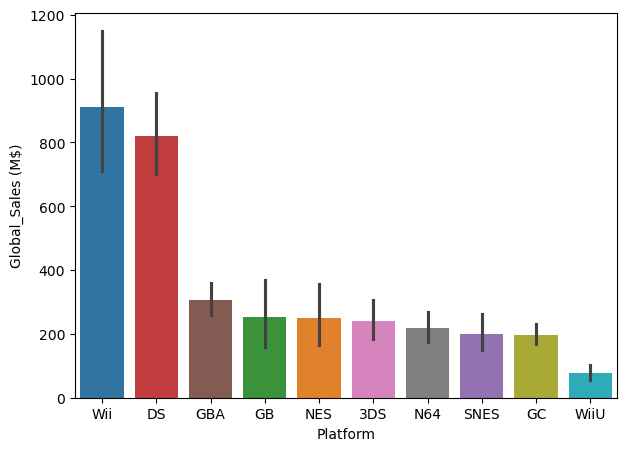

In [56]:
plt.figure(figsize=(7, 5))
sns.barplot(data=NintendoConsoles, x="Platform", y="Global_Sales (M$)", estimator=np.sum, hue="Platform", order=["Wii", "DS", "GBA", "GB", "NES", "3DS", "N64", "SNES", "GC", "WiiU"])
plt.show()

#3 Visualize the Sales for the Wii for every year, provide further commentary on your findings 
- From 2006 to 2009, this represent an uptick on global sales with Wii products from year to year 
- From 2010 to 2015, the global sales for years gradually declined
- The WiiU, the successor to the WiiU was released in late 2012, this could explain why sales declined from 2012 onward as Nintendo probably focused their efforts to promoting the WiiU

In [57]:
Wii = videogames[videogames["Platform"] == "Wii"]

In [58]:
Wii

,Name,Platform,Year,Genre,Publisher,NA_Sales (M$),EU_Sales (M$),JP_Sales (M$),Other_Sales (M$),Global_Sales (M$),Nintendo,NintendoConsole,Xbox,XboxConsole,PlayStation,PlayStationConsole,HandHeld,HandheldConsole
0,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74,True,1,False,0,False,0,False,0
2,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82,True,1,False,0,False,0,False,0
3,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00,True,1,False,0,False,0,False,0
7,Wii Play,Wii,2006,Misc,Nintendo,14.03,9.20,2.93,2.85,29.02,True,1,False,0,False,0,False,0
8,New Super Mario Bros. Wii,Wii,2009,Platform,Nintendo,14.59,7.06,4.70,2.26,28.62,True,1,False,0,False,0,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16517,Teenage Mutant Ninja Turtles,Wii,2007,Action,Konami Digital Entertainment,0.00,0.01,0.00,0.00,0.01,True,1,False,0,False,0,False,0
16552,Mahou Sensei Negima!? Neo-Pactio Fight!!,Wii,2007,Fighting,Marvelous Interactive,0.00,0.00,0.01,0.00,0.01,True,1,False,0,False,0,False,0
16573,Mini Desktop Racing,Wii,2007,Racing,Popcorn Arcade,0.01,0.00,0.00,0.00,0.01,True,1,False,0,False,0,False,0
16574,Yattaman Wii: BikkuriDokkiri Machine de Mou Ra...,Wii,2008,Racing,Takara Tomy,0.00,0.00,0.01,0.00,0.01,True,1,False,0,False,0,False,0


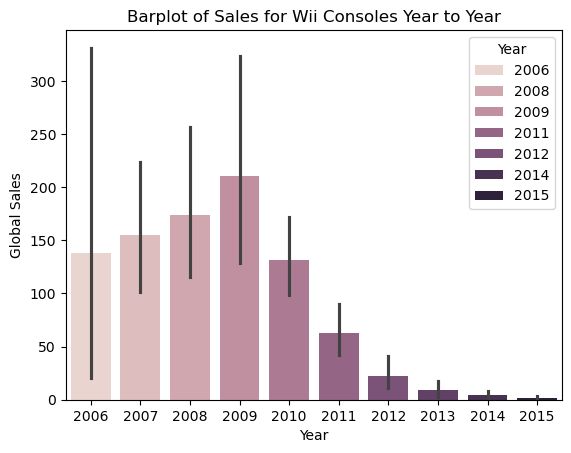

In [59]:
sns.barplot(data=Wii, x="Year", y="Global_Sales (M$)", estimator=np.sum, hue="Year")
plt.title("Barplot of Sales for Wii Consoles Year to Year")
plt.xlabel("Year")
plt.ylabel("Global Sales")
plt.show()

#4 Create a barplot of sales for the wii games by genre
- Clearly Sports is the most popular genre in Wii Games, however how much is this is attributed to the success of Wii Sports?

In [60]:
group1 = Wii.groupby(["Genre"])["Global_Sales (M$)"].sum().sort_values(ascending=False)

In [61]:
group1

Genre
Sports          289.95
Misc            217.43
Action          110.48
Platform         90.68
Racing           61.24
Simulation       36.62
Shooter          26.34
Fighting         23.82
Adventure        18.33
Puzzle           15.63
Role-Playing     14.06
Strategy          5.23
Name: Global_Sales (M$), dtype: float64

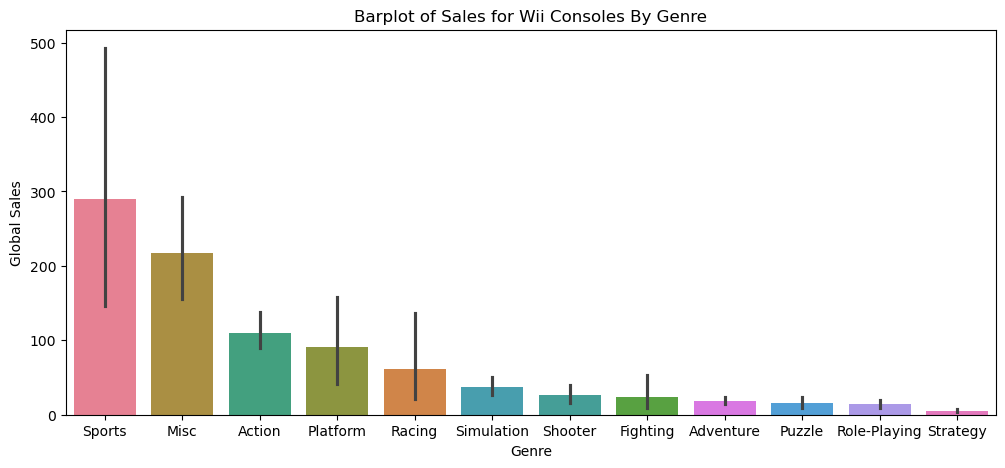

In [62]:
plt.figure(figsize=(12, 5))
sns.barplot(data=Wii, x="Genre", y="Global_Sales (M$)", estimator=np.sum, hue="Genre", order=["Sports", "Misc", "Action", "Platform", "Racing", "Simulation", "Shooter", "Fighting", "Adventure", "Puzzle", "Role-Playing", "Strategy"])
plt.title("Barplot of Sales for Wii Consoles By Genre")
plt.xlabel("Genre")
plt.ylabel("Global Sales")
plt.show()

In [63]:
#wii sports 

In [64]:
WiiSportsGames = videogames[(videogames["Platform"] == "Wii") & (videogames["Genre"] == "Sports")]

In [65]:
WiiSportsGames

,Name,Platform,Year,Genre,Publisher,NA_Sales (M$),EU_Sales (M$),JP_Sales (M$),Other_Sales (M$),Global_Sales (M$),Nintendo,NintendoConsole,Xbox,XboxConsole,PlayStation,PlayStationConsole,HandHeld,HandheldConsole
0,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74,True,1,False,0,False,0,False,0
3,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00,True,1,False,0,False,0,False,0
13,Wii Fit,Wii,2007,Sports,Nintendo,8.94,8.03,3.60,2.15,22.72,True,1,False,0,False,0,False,0
14,Wii Fit Plus,Wii,2009,Sports,Nintendo,9.09,8.59,2.53,1.79,22.00,True,1,False,0,False,0,False,0
85,Mario & Sonic at the Olympic Games,Wii,2007,Sports,Sega,2.58,3.90,0.66,0.91,8.06,True,1,False,0,False,0,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15756,Turbo: Super Stunt Squad,Wii,2013,Sports,D3Publisher,0.00,0.02,0.00,0.00,0.02,True,1,False,0,False,0,False,0
16087,Major Dream: Major Wii Nagero! Gyroball!!,Wii,2008,Sports,Takara Tomy,0.00,0.00,0.01,0.00,0.01,True,1,False,0,False,0,False,0
16218,Family Jockey,Wii,2008,Sports,Namco Bandai Games,0.00,0.00,0.01,0.00,0.01,True,1,False,0,False,0,False,0
16437,The Cages: Pro Style Batting Practice,Wii,2010,Sports,Konami Digital Entertainment,0.01,0.00,0.00,0.00,0.01,True,1,False,0,False,0,False,0


#Find the global sales for sports games by year 
- The majority of the sports games sales occured in 2006 and 2009, during the first year of the wii and the height of the Wiis popularity

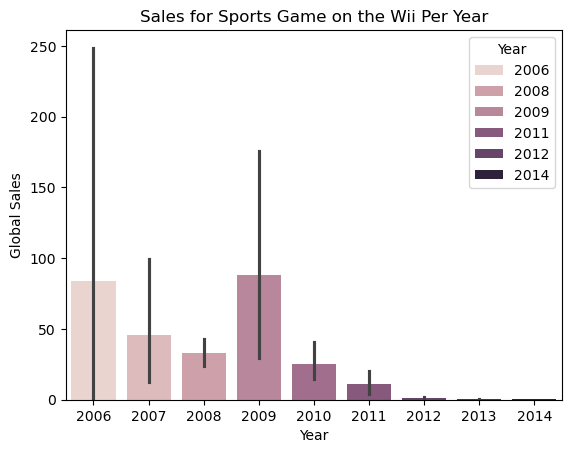

In [66]:
sns.barplot(data=WiiSportsGames, x="Year", y="Global_Sales (M$)", estimator=np.sum, hue="Year")
plt.title("Sales for Sports Game on the Wii Per Year")
plt.xlabel("Year")
plt.ylabel("Global Sales")
plt.show()

#Find the top 10 Sports Titles that Generate the Most Sales
 - My hypothesis that the number of global sales might be skewed due to the overwhelming popularity of the wii sports franchise is plausible
- Approxiately 40% of sales for Sports titles are either Wii Sports or Wii Sports Resort

In [67]:
WiiSportsGamesTop = WiiSportsGames.groupby("Name").sum()["Global_Sales (M$)"].reset_index()

In [68]:
WiiSportsGamesTop.sort_values("Global_Sales (M$)", ascending=False).head(10)

,Name,Global_Sales (M$)
241,Wii Sports,82.74
242,Wii Sports Resort,33.00
239,Wii Fit,22.72
240,Wii Fit Plus,22.00
131,Mario & Sonic at the Olympic Games,8.06
253,Zumba Fitness,6.81
132,Mario & Sonic at the Olympic Winter Games,4.58
63,EA Sports Active,3.92
130,Mario & Sonic at the London 2012 Olympic Games,3.78
254,Zumba Fitness 2,2.88


In [69]:
WiiSportsPercentage = (82.74+33.00)/289.95
print(WiiSportsPercentage)

0.3991722710812209


In [70]:
#What are the top ten selling Wii Games of all Time? 

In [71]:
TopWiiGames = Wii.groupby("Name").sum()["Global_Sales (M$)"].reset_index()

In [72]:
TopWiiGames.sort_values("Global_Sales (M$)", ascending=False).head(10)

,Name,Global_Sales (M$)
1235,Wii Sports,82.74
621,Mario Kart Wii,35.82
1236,Wii Sports Resort,33.00
1233,Wii Play,29.02
757,New Super Mario Bros. Wii,28.62
1229,Wii Fit,22.72
1230,Wii Fit Plus,22.00
1041,Super Smash Bros. Brawl,13.04
1033,Super Mario Galaxy,11.52
522,Just Dance 3,10.26


In [73]:
#What are the top ten selling Nintendo games of all time? 

In [317]:
NintendoGamesTop = NintendoConsoles.groupby("Name").sum()["Global_Sales (M$)"].reset_index()

In [75]:
NintendoGamesTop.sort_values("Global_Sales (M$)", ascending=False).head(10)

,Name,Global_Sales (M$)
5098,Wii Sports,82.74
4348,Super Mario Bros.,45.31
4547,Tetris,35.84
2588,Mario Kart Wii,35.82
5100,Wii Sports Resort,33.00
3472,Pokemon Red/Pokemon Blue,31.37
3145,New Super Mario Bros.,30.01
5096,Wii Play,29.02
3148,New Super Mario Bros. Wii,28.62
1215,Duck Hunt,28.31


#return a line graph that populates sales data for Nintendo
- From 1985 to 2009, sales went up every year
- 2009 is the peak of Nintendo, they have not recovered
- reason for sales decline is unclear, but there is a consistent decline in sales from 2009 onward

In [76]:
yearly_sales = NintendoConsoles.groupby("Year")["Global_Sales (M$)"].sum()

In [318]:
yearly_sales

Year
1983     10.96
1984     50.09
1985     53.46
1986     36.41
1987     19.76
1988     46.44
1989     72.83
1990     46.79
1991     27.89
1992     60.44
1993     43.62
1994     47.36
1995     35.81
1996     86.06
1997     46.87
1998     76.40
1999     96.23
2000     53.83
2001    100.42
2002    126.39
2003    107.39
2004    119.14
2005    191.67
2006    275.70
2007    306.82
2008    322.05
2009    332.43
2010    219.78
2011    152.74
2012    103.34
2013     89.04
2014     70.10
2015     44.92
Name: Global_Sales (M$), dtype: float64

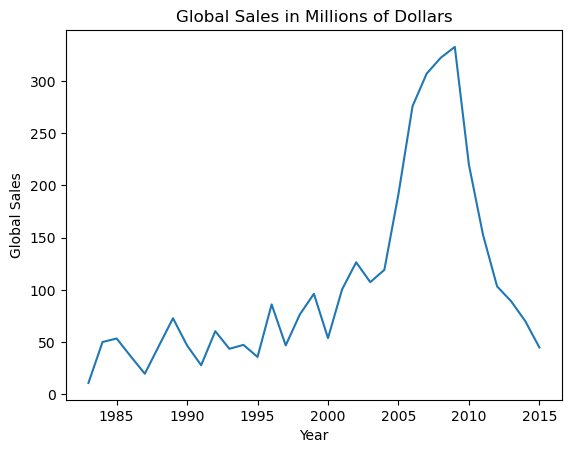

In [77]:
plt.plot(yearly_sales.index, yearly_sales.values)
plt.title("Global Sales in Millions of Dollars")
plt.xlabel("Year")
plt.ylabel("Global Sales")
plt.show()

In [80]:
#return a line graph for global sales for video games by year 

In [81]:
yearly_sales_stats = videogames.groupby("Year")["Global_Sales (M$)"].sum()

In [82]:
yearly_sales_stats

Year
1980     11.38
1981     35.77
1982     28.86
1983     16.79
1984     50.36
1985     53.94
1986     37.07
1987     21.74
1988     47.22
1989     73.45
1990     49.39
1991     32.23
1992     76.16
1993     45.98
1994     79.17
1995     88.11
1996    199.15
1997    200.98
1998    256.47
1999    251.27
2000    201.56
2001    331.47
2002    395.52
2003    357.85
2004    414.01
2005    458.51
2006    521.04
2007    609.92
2008    678.90
2009    667.30
2010    600.29
2011    515.80
2012    363.49
2013    368.11
2014    337.03
2015    264.44
Name: Global_Sales (M$), dtype: float64

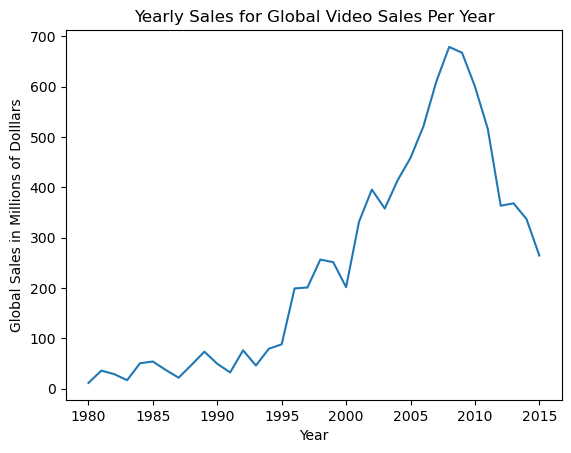

In [83]:
plt.title("Yearly Sales for Global Video Sales Per Year")
plt.plot(yearly_sales_stats.index, yearly_sales_stats.values)
plt.xlabel("Year")
plt.ylabel("Global Sales in Millions of Dolllars")
plt.show()

In [84]:
#dive a little deep for statistics in 2008 where videogames sales peaked 

In [85]:
sales2008 = videogames[videogames["Year"] == 2008]

In [86]:
sales2008

,Name,Platform,Year,Genre,Publisher,NA_Sales (M$),EU_Sales (M$),JP_Sales (M$),Other_Sales (M$),Global_Sales (M$),Nintendo,NintendoConsole,Xbox,XboxConsole,PlayStation,PlayStationConsole,HandHeld,HandheldConsole
2,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82,True,1,False,0,False,0,False,0
39,Super Smash Bros. Brawl,Wii,2008,Fighting,Nintendo,6.75,2.61,2.66,1.02,13.04,True,1,False,0,False,0,False,0
51,Grand Theft Auto IV,X360,2008,Action,Take-Two Interactive,6.76,3.10,0.14,1.03,11.02,False,0,True,1,False,0,False,0
56,Grand Theft Auto IV,PS3,2008,Action,Take-Two Interactive,4.76,3.76,0.44,1.62,10.57,False,0,False,0,True,1,False,0
88,Pokémon Platinum Version,DS,2008,Role-Playing,Nintendo,2.82,1.78,2.69,0.55,7.84,True,1,False,0,False,0,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16575,Neo Angelique Special,PSP,2008,Adventure,Tecmo Koei,0.00,0.00,0.01,0.00,0.01,False,0,False,0,False,0,True,1
16580,Real Rode,PS2,2008,Adventure,Kadokawa Shoten,0.00,0.00,0.01,0.00,0.01,False,0,False,0,True,1,False,0
16588,Mega Brain Boost,DS,2008,Puzzle,Majesco Entertainment,0.01,0.00,0.00,0.00,0.01,True,1,False,0,False,0,False,0
16592,Plushees,DS,2008,Simulation,Destineer,0.01,0.00,0.00,0.00,0.01,True,1,False,0,False,0,False,0


In [87]:
#the Wii is the best selling console in 2008, followed by the DS, X360 and PS3
#It is fascinating to the see the the nintendo DS outsold the PS3 and Xbox360

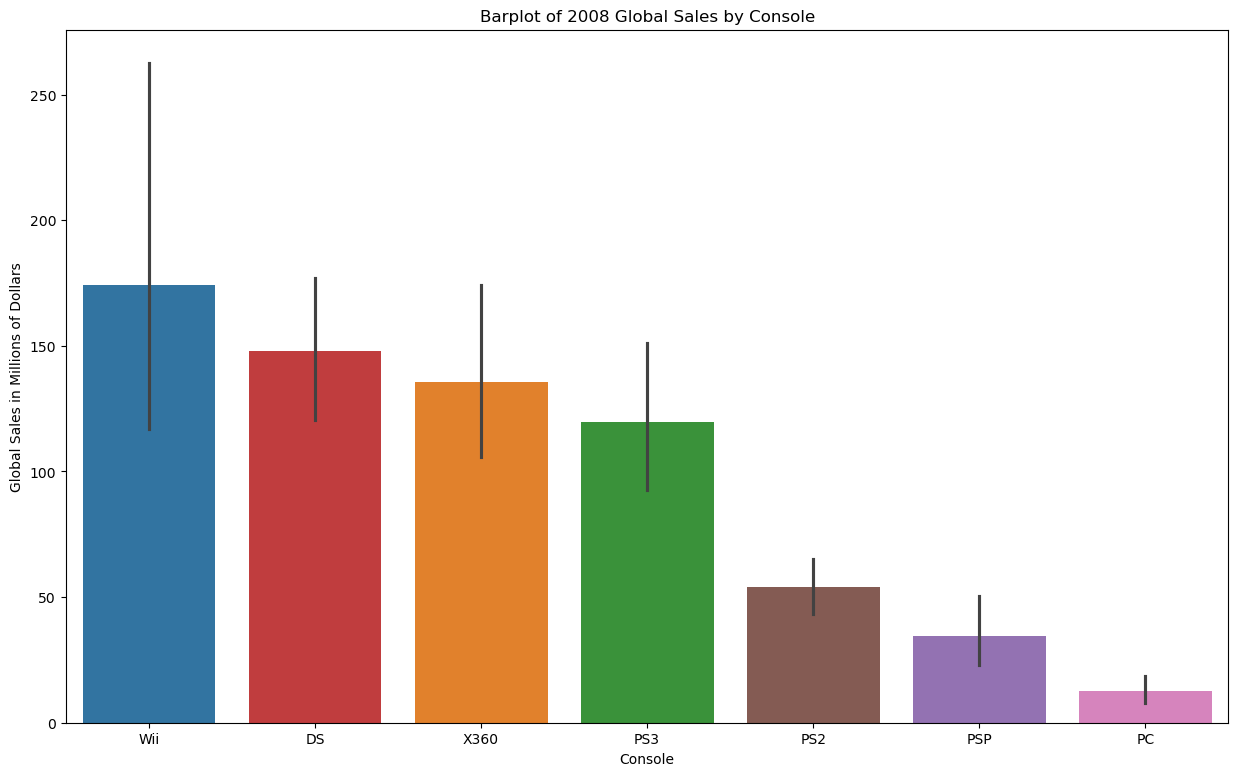

In [88]:
plt.figure(figsize=(15, 9))
plt.title("Barplot of 2008 Global Sales by Console")
sns.barplot(data=sales2008, x="Platform", y="Global_Sales (M$)", estimator=np.sum, hue="Platform", order=["Wii", "DS", "X360", "PS3", "PS2", "PSP", "PC"])
plt.xlabel("Console")
plt.ylabel("Global Sales in Millions of Dollars")
plt.show()

In [89]:
#break down 2008 game sales by the DS, curious to find out why the sales for the Nintendo DS was better than the X360

In [90]:
sales2008DS = videogames[(videogames["Platform"] == "DS") & (videogames["Year"] == 2008)]

In [91]:
sales2008DS

,Name,Platform,Year,Genre,Publisher,NA_Sales (M$),EU_Sales (M$),JP_Sales (M$),Other_Sales (M$),Global_Sales (M$),Nintendo,NintendoConsole,Xbox,XboxConsole,PlayStation,PlayStationConsole,HandHeld,HandheldConsole
88,Pokémon Platinum Version,DS,2008,Role-Playing,Nintendo,2.82,1.78,2.69,0.55,7.84,True,1,False,0,False,0,False,0
189,Mario & Sonic at the Olympic Games,DS,2008,Sports,Sega,1.64,2.48,0.44,0.58,5.14,True,1,False,0,False,0,False,0
380,Guitar Hero: On Tour,DS,2008,Misc,Activision,2.11,1.01,0.01,0.35,3.48,True,1,False,0,False,0,False,0
399,Professor Layton and the Unwound Future,DS,2008,Puzzle,Nintendo,0.65,1.61,0.82,0.28,3.36,True,1,False,0,False,0,False,0
432,Rhythm Heaven,DS,2008,Misc,Nintendo,0.58,0.51,1.93,0.14,3.17,True,1,False,0,False,0,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16515,Knights in the Nightmare: DHE Series Special Pack,DS,2008,Role-Playing,Sting,0.00,0.00,0.01,0.00,0.01,True,1,False,0,False,0,False,0
16525,Blazer Drive,DS,2008,Role-Playing,Sega,0.00,0.00,0.01,0.00,0.01,True,1,False,0,False,0,False,0
16527,Hoshizora no Comic Garden,DS,2008,Adventure,D3Publisher,0.00,0.00,0.01,0.00,0.01,True,1,False,0,False,0,False,0
16588,Mega Brain Boost,DS,2008,Puzzle,Majesco Entertainment,0.01,0.00,0.00,0.00,0.01,True,1,False,0,False,0,False,0


There is a balanced diverisifaction of sales for misc, simulation, role playing, action and adventure

In [92]:
sales2008DSpivot = sales2008DS.pivot_table(index="Genre", values="Global_Sales (M$)", aggfunc="sum").sort_values(by="Global_Sales (M$)", ascending=False)

In [93]:
sales2008DSpivot

,Global_Sales (M$)
Genre,
Misc,27.72
Simulation,26.67
Role-Playing,23.69
Action,17.07
Adventure,15.54
Sports,13.29
Puzzle,9.46
Platform,7.65
Strategy,2.83


In [96]:
#break down 2008 Sales by GEnre

In [97]:
sales2008genre = sales2008.groupby("Genre")["Global_Sales (M$)"].sum()

In [98]:
sales2008genre

Genre
Action          136.39
Adventure        25.02
Fighting         35.38
Misc             87.03
Platform         35.70
Puzzle           15.59
Racing           70.66
Role-Playing     59.83
Shooter          59.51
Simulation       46.76
Sports           95.34
Strategy         11.69
Name: Global_Sales (M$), dtype: float64

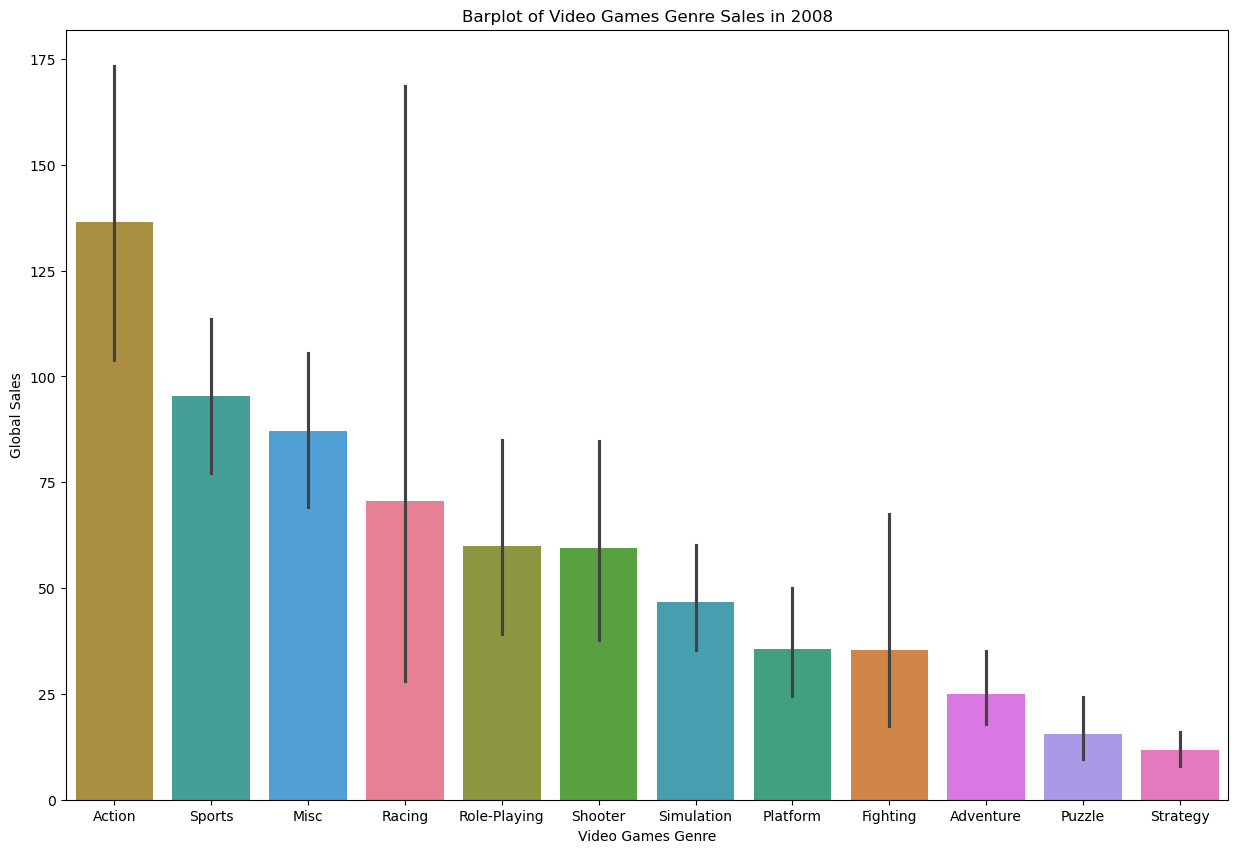

In [99]:
plt.figure(figsize=(15, 10))
sns.barplot(data=sales2008, x="Genre", y="Global_Sales (M$)", estimator=np.sum, hue="Genre", order=["Action", "Sports", "Misc", "Racing", "Role-Playing", "Shooter", "Simulation", "Platform", "Fighting", "Adventure", "Puzzle", "Strategy"])
plt.title("Barplot of Video Games Genre Sales in 2008")
plt.xlabel("Video Games Genre")
plt.ylabel("Global Sales")
plt.show()

In [100]:
Sales2008GenreAction = videogames[(videogames["Genre"] == "Action") & (videogames["Year"] == 2008)]

In [101]:
Sales2008GenreAction

,Name,Platform,Year,Genre,Publisher,NA_Sales (M$),EU_Sales (M$),JP_Sales (M$),Other_Sales (M$),Global_Sales (M$),Nintendo,NintendoConsole,Xbox,XboxConsole,PlayStation,PlayStationConsole,HandHeld,HandheldConsole
51,Grand Theft Auto IV,X360,2008,Action,Take-Two Interactive,6.76,3.10,0.14,1.03,11.02,False,0,True,1,False,0,False,0
56,Grand Theft Auto IV,PS3,2008,Action,Take-Two Interactive,4.76,3.76,0.44,1.62,10.57,False,0,False,0,True,1,False,0
144,Metal Gear Solid 4: Guns of the Patriots,PS3,2008,Action,Konami Digital Entertainment,2.63,1.74,0.83,0.83,6.03,False,0,False,0,True,1,False,0
324,LEGO Indiana Jones: The Original Adventures,X360,2008,Action,Activision,2.40,1.03,0.00,0.36,3.78,False,0,True,1,False,0,False,0
394,LEGO Batman: The Videogame,X360,2008,Action,Warner Bros. Interactive Entertainment,2.03,1.03,0.00,0.32,3.38,False,0,True,1,False,0,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16147,Chokkan! Asonde Relaxuma,DS,2008,Action,Rocket Company,0.00,0.00,0.01,0.00,0.01,True,1,False,0,False,0,False,0
16176,San-X Character Channel: All-Star Daishuugou!,DS,2008,Action,MTO,0.00,0.00,0.01,0.00,0.01,True,1,False,0,False,0,False,0
16259,Simple DS Series Vol. 41: The Bakudan Shori-Han,DS,2008,Action,D3Publisher,0.00,0.00,0.01,0.00,0.01,True,1,False,0,False,0,False,0
16444,Madagascar: Escape 2 Africa,PC,2008,Action,Activision,0.01,0.00,0.00,0.00,0.01,False,0,False,0,False,0,False,0


In [102]:
#abuot 60% of global sales for action games belong to either the Xbox360 or PS3

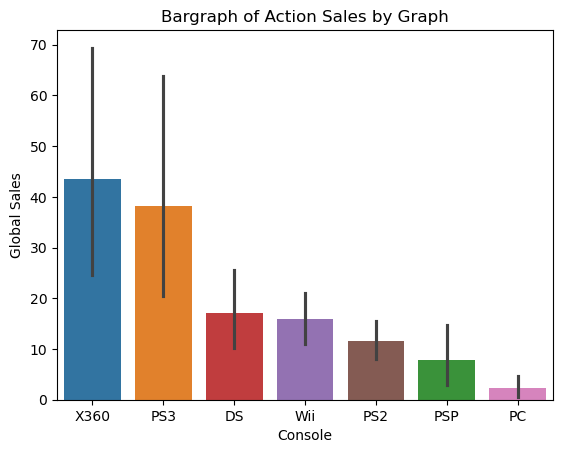

In [103]:
plt.title("Bargraph of Action Sales by Graph")
sns.barplot(data=Sales2008GenreAction, x="Platform", y="Global_Sales (M$)", estimator=np.sum, hue="Platform", order=["X360", "PS3", "DS","Wii", "PS2", "PSP", "PC"])
plt.xlabel("Console")
plt.ylabel("Global Sales")
plt.show()

In [104]:
Sales2008ConsoleAction = Sales2008GenreAction.groupby("Platform")["Global_Sales (M$)"].sum().sort_values(ascending=False)

In [105]:
Sales2008ConsoleAction

Platform
X360    43.61
PS3     38.14
DS      17.07
Wii     15.89
PS2     11.51
PSP      7.82
PC       2.35
Name: Global_Sales (M$), dtype: float64

In [106]:
percentage  = (43.61+38.14)/136.39
print(percentage)

0.5993841190703131


In [107]:
#this is interesting, the maximum amount of money made per game in 2008 was made in the racing genre. 

In [108]:
sales2008.pivot_table(index="Genre", values="Global_Sales (M$)", aggfunc="max").sort_values(by="Global_Sales (M$)", ascending=False)

,Global_Sales (M$)
Genre,
Racing,35.82
Fighting,13.04
Action,11.02
Role-Playing,7.84
Shooter,7.37
Platform,5.92
Sports,5.14
Simulation,4.68
Misc,3.65


In [109]:
Sales2008Racing = videogames[(videogames["Year"]== 2008) & (videogames["Genre"] == "Racing")]

In [110]:
Sales2008Racing

,Name,Platform,Year,Genre,Publisher,NA_Sales (M$),EU_Sales (M$),JP_Sales (M$),Other_Sales (M$),Global_Sales (M$),Nintendo,NintendoConsole,Xbox,XboxConsole,PlayStation,PlayStationConsole,HandHeld,HandheldConsole
2,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82,True,1,False,0,False,0,False,0
621,Pure,X360,2008,Racing,Disney Interactive Studios,1.38,0.85,0.00,0.25,2.48,False,0,True,1,False,0,False,0
628,Midnight Club: Los Angeles,PS3,2008,Racing,Take-Two Interactive,1.55,0.54,0.05,0.31,2.45,False,0,False,0,True,1,False,0
674,Midnight Club: Los Angeles,X360,2008,Racing,Take-Two Interactive,1.68,0.46,0.01,0.20,2.35,False,0,True,1,False,0,False,0
801,Need For Speed: Undercover,PS3,2008,Racing,Electronic Arts,0.63,1.02,0.05,0.39,2.08,False,0,False,0,True,1,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15970,SBK Superbike World Championship,PS2,2008,Racing,Black Bean Games,0.01,0.01,0.00,0.00,0.02,False,0,False,0,True,1,False,0
16245,FlatOut: Ultimate Carnage,PC,2008,Racing,Empire Interactive,0.00,0.01,0.00,0.00,0.01,False,0,False,0,False,0,False,0
16490,SBK Superbike World Championship,PSP,2008,Racing,Black Bean Games,0.01,0.00,0.00,0.00,0.01,False,0,False,0,False,0,True,1
16574,Yattaman Wii: BikkuriDokkiri Machine de Mou Ra...,Wii,2008,Racing,Takara Tomy,0.00,0.00,0.01,0.00,0.01,True,1,False,0,False,0,False,0


In [111]:
#51% of sales for racing games in 2008 belong to mario kart wii

In [112]:
sales2008RacingTop10 = Sales2008Racing.pivot_table(index="Name", values="Global_Sales (M$)").sort_values(by="Global_Sales (M$)", ascending=False).head(10)

In [113]:
sales2008RacingTop10

,Global_Sales (M$)
Name,
Mario Kart Wii,35.820000
Midnight Club: Los Angeles,2.400000
Pure,1.690000
Burnout Paradise,1.665000
MotorStorm: Pacific Rift,1.370000
GRID,0.995000
Midnight Club: LA Remix,0.990000
Need For Speed: Undercover,0.988571
Need for Speed: ProStreet,0.780000


In [114]:
mariokartpercentage = (35.82)/70.66
print(mariokartpercentage)

0.5069346164732522


Conclusions from Exploratory Data Analysis

1. The nintendo consoles that overwhemling generate the most sales are the Wii and Nintedo DS
2. The window of time that encapsulated the peak of Nintendo wii sales was from 2006 to 2009
3. 40% of global sales for Nintendo Wii Sports games belonged to Wii Sports properties (Will Sports and Wii Sports Resort)
4. The orginal Wii Sports is clearly the best selling nintendo game of all time, it outsells the next closest game (original super mario bros by 40 million dollars)
5. The action genre grossed the most sales in 2008
6. About 60% of global sales for action games belong to either the Xbox360 or PS3
7. 51% of sales for racing games in 2008 belong to mario kart wii

In [115]:
#Machine Learning Tasks 

Simple Linear Regression- is there a correalation between North American Sales and Global Sales for each video games 
Steps
1. Create a subset of the dataframe for the columns NA_Sales (M$) and Global_Sales (M$)
2. Specifiy that the x axis is NA_Sales (M$) and Global_Sales (M$)
3. perform train test split (70% training, 30% test)
4. use linear regression and build the model
5. Generate y-predicted value 
6. visualize the results
7. Use r2 score to Determine relationship

In [116]:
# Create a subset of the dataframe for the columns NA_Sales (M$) and Global_Sales (M$)

In [117]:
regression1 = videogames[["NA_Sales (M$)", "Global_Sales (M$)"]]

In [118]:
regression1

,NA_Sales (M$),Global_Sales (M$)
0,41.49,82.74
1,29.08,40.24
2,15.85,35.82
3,15.75,33.00
4,11.27,31.37
...,...,...
16593,0.01,0.01
16594,0.01,0.01
16595,0.00,0.01
16596,0.00,0.01


In [119]:
#Specifiy that the x axis is NA_Sales (M$) and Global_Sales (M$)

In [120]:
X = regression1.iloc[:, :-1].values
Y = regression1.iloc[:, -1].values

In [121]:
X

array([[4.149e+01],
       [2.908e+01],
       [1.585e+01],
       ...,
       [0.000e+00],
       [0.000e+00],
       [1.000e-02]])

In [122]:
Y

array([8.274e+01, 4.024e+01, 3.582e+01, ..., 1.000e-02, 1.000e-02,
       1.000e-02])

In [123]:
#perform train and test split 

In [124]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.30, random_state=0)

In [125]:
X_train

array([[0.  ],
       [0.11],
       [0.  ],
       ...,
       [0.05],
       [0.08],
       [0.4 ]])

In [126]:
X_test

array([[0.11],
       [0.04],
       [0.  ],
       ...,
       [0.05],
       [0.17],
       [4.79]])

In [127]:
Y_train

array([0.05, 0.12, 0.06, ..., 0.11, 0.09, 0.73])

In [128]:
Y_test

array([0.12, 0.06, 0.02, ..., 0.13, 0.23, 7.37])

In [129]:
#use linear regression and build a model

In [130]:
from sklearn.linear_model import LinearRegression
regressor = LinearRegression()
regressor.fit(X, Y)

LinearRegression()

In [131]:
regressor

LinearRegression()

In [132]:
y_pred = regressor.predict(X_test)

In [133]:
y_pred

array([0.261264  , 0.1357171 , 0.06397601, ..., 0.15365237, 0.36887564,
       8.65497144])

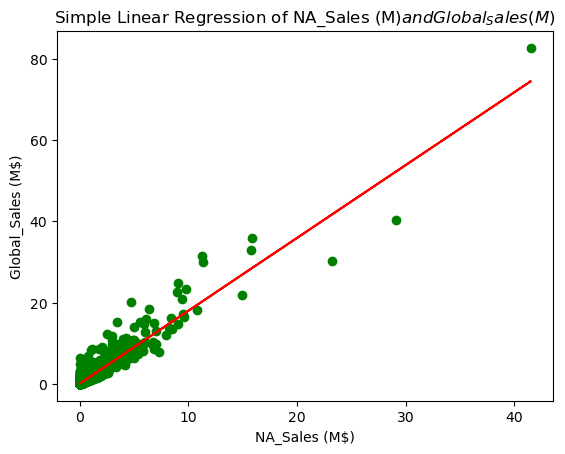

In [134]:
plt.scatter(X_train, Y_train, color="green")
plt.plot(X_train, regressor.predict(X_train), color="red")
plt.title("Simple Linear Regression of NA_Sales (M$) and Global_Sales (M$)")
plt.xlabel("NA_Sales (M$)")
plt.ylabel("Global_Sales (M$)")
plt.show()

In [135]:
from sklearn.metrics import r2_score 
r2_score(y_pred, Y_test)

0.8503212797288002

Conclusions from Simple Linear Regression
- The North American Sales of a respective video game are a strong indicator of how the video game will sell globally, the correalation between both variables is 85.0% 
- It would be interesting to perform a k-means cluster to understand the distribution of these data points better, the data seems to be tightly packed between the following parameters (0-10 North American Sales and 0 to 20 Global Sales)

2. ***Multiple Linear Regression- How accurately can I predict the global sales of a video games based on how the games sells in North America, EU and Japan***
<p>Steps:<p> 

<p>Create a subset of the dataframe for the columns<p> 
<p>Specifiy that the x axis is All of the sales except for global sales and the y axis is global sales<p>
<p>perform train test split (70% training, 30% test)<p>
<p>use linear regression and build the model<p>
<p>Generate y-predicted value<p>
<p>visualize the results<p>
<p>Create pandas dataframe that capture the predicted value, actual value and difference for each data pointreturn r2 score<p>

In [136]:
#create slice of the dataframe for the required columns

In [137]:
Mult1 = videogames[["NA_Sales (M$)", "EU_Sales (M$)", "JP_Sales (M$)", "Other_Sales (M$)", "Global_Sales (M$)"]] 	 	

In [138]:
#split into x and y values 

In [139]:
X = Mult1.iloc[:, :-1].values
Y = Mult1.iloc[:, -1].values

In [140]:
#perform train and test split 

In [141]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.30, random_state=0)

In [142]:
#build linear regression model

In [143]:
from sklearn.linear_model import LinearRegression
regressor = LinearRegression()
regressor.fit(X, Y)

LinearRegression()

In [144]:
#create y_predicted values, predictions of y output based on x values not trainied in the algorithm 

In [145]:
y_pred = regressor.predict(X_test)

In [146]:
y_pred

array([0.12030953, 0.06031738, 0.02031698, ..., 0.13031301, 0.23030628,
       7.37978636])

In [147]:
#visualize

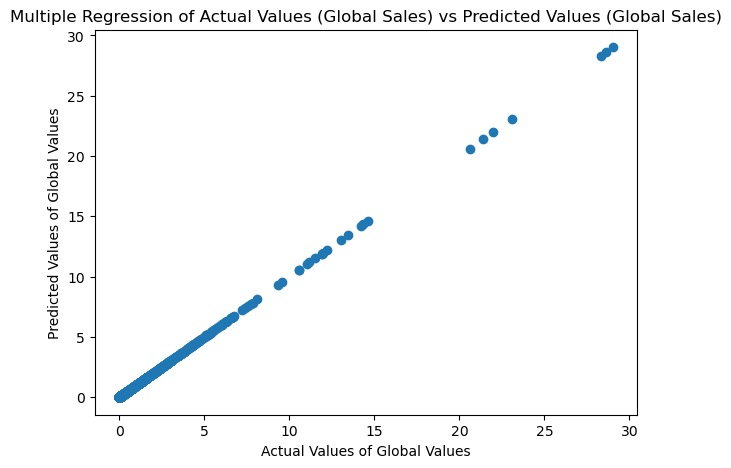

In [148]:
plt.figure(figsize=(7, 5))
plt.title("Multiple Regression of Actual Values (Global Sales) vs Predicted Values (Global Sales)")
plt.xlabel("Actual Values of Global Values")
plt.ylabel("Predicted Values of Global Values")
plt.scatter(y_pred, Y_test)
plt.show()

In [149]:
MultDataFrame = pd.DataFrame({"Actual": Y_test, "Predicted": y_pred, "Difference": Y_test-y_pred})

In [150]:
MultDataFrame

,Actual,Predicted,Difference
0,0.12,0.120310,-0.000310
1,0.06,0.060317,-0.000317
2,0.02,0.020317,-0.000317
3,0.11,0.110311,-0.000311
4,0.62,0.620239,-0.000239
...,...,...,...
4779,0.19,0.180307,0.009693
4780,0.06,0.050317,0.009683
4781,0.13,0.130313,-0.000313
4782,0.23,0.230306,-0.000306


In [151]:
from sklearn.metrics import r2_score
r2_score(Y_test, y_pred)

0.9999865788263551

Conclusions from Multiple Regression Analysis
- The model's accuracy is 99.6%, which is shockingly accurate, most models aren't nearly this accurate
- The model is telling us that there is an association of 99.6% between the values from the sales in North America, Japan, EU and Other and the global sales, almost too good to be true

#3. Perform K-Means Cluster, categorize video games sales data with North AMerica on x axis and global sales on y axis
1. Create a subset of the dataframe for the columns NA_Sales (M$) and Global_Sales (M$)
2. Specifiy that the x axis is NA_Sales (M$) and Global_Sales (M$)
3. choose number of clusters to represent K 
4. define kmeans and y-Kmeans to represent k means algorithms 
5. create clusterplot to visualize data in clusters with centroids 
6. conclude on the patterns of the data

<p>This article on medium gives a good overview of K-Means Clustering in Python: https://medium.com/@zalarushirajsinh07/the-elbow-method-finding-the-optimal-number-of-clusters-d297f5aeb189<p>

In [164]:
#create subset 

In [153]:
videogames

,Name,Platform,Year,Genre,Publisher,NA_Sales (M$),EU_Sales (M$),JP_Sales (M$),Other_Sales (M$),Global_Sales (M$),Nintendo,NintendoConsole,Xbox,XboxConsole,PlayStation,PlayStationConsole,HandHeld,HandheldConsole
0,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74,True,1,False,0,False,0,False,0
1,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,True,1,False,0,False,0,False,0
2,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82,True,1,False,0,False,0,False,0
3,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00,True,1,False,0,False,0,False,0
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,True,1,False,0,False,0,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16593,Woody Woodpecker in Crazy Castle 5,GBA,2002,Platform,Kemco,0.01,0.00,0.00,0.00,0.01,True,1,False,0,False,0,True,1
16594,Men in Black II: Alien Escape,GC,2003,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01,True,1,False,0,False,0,False,0
16595,SCORE International Baja 1000: The Official Game,PS2,2008,Racing,Activision,0.00,0.00,0.00,0.00,0.01,False,0,False,0,True,1,False,0
16596,Know How 2,DS,2010,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01,True,1,False,0,False,0,False,0


In [154]:
data = videogames[["NA_Sales (M$)", "Global_Sales (M$)"]]

In [155]:
data

,NA_Sales (M$),Global_Sales (M$)
0,41.49,82.74
1,29.08,40.24
2,15.85,35.82
3,15.75,33.00
4,11.27,31.37
...,...,...
16593,0.01,0.01
16594,0.01,0.01
16595,0.00,0.01
16596,0.00,0.01


In [156]:
#ensure that both columns are x values 

In [157]:
X = data.iloc[:, [0, 1]].values

In [158]:
X

array([[4.149e+01, 8.274e+01],
       [2.908e+01, 4.024e+01],
       [1.585e+01, 3.582e+01],
       ...,
       [0.000e+00, 1.000e-02],
       [0.000e+00, 1.000e-02],
       [1.000e-02, 1.000e-02]])

In [159]:
#determine the number of cluster that should be used for this analysis 

In [ ]:
#use five clusters the elbow at five 

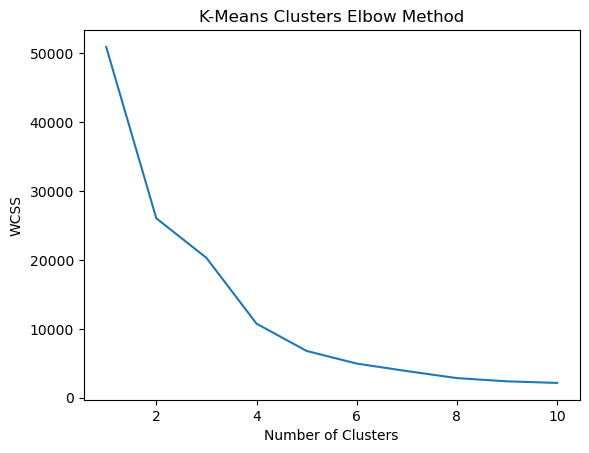

In [163]:
from sklearn.cluster import KMeans
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init="k-means++", random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)
plt.plot(range(1, 11), wcss)
plt.title("K-Means Clusters Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

In [165]:
#define kmeans and y_kmeans 
#kmeans defines the number of clustesr 
#ykmeans returns the cluster that the row belong 0, 1, 2, 3, 4

In [166]:
kmeans = KMeans(n_clusters=5, init="k-means++", random_state=42)
y_kmeans = kmeans.fit_predict(X)

In [167]:
kmeans

KMeans(n_clusters=5, random_state=42)

In [168]:
y_kmeans

array([2, 4, 4, ..., 0, 0, 0])

In [169]:
#return the visualization and provide conclusions 

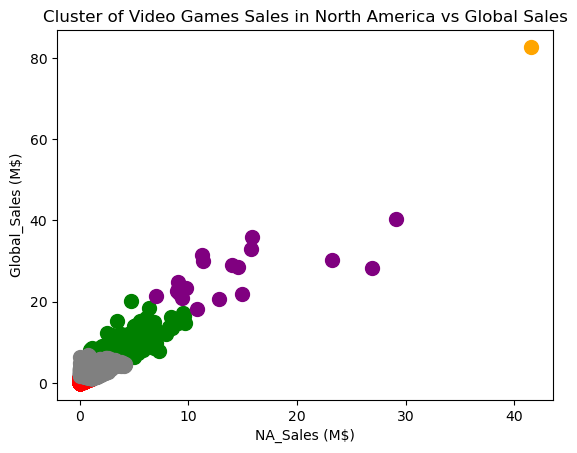

In [176]:
plt.scatter(X[y_kmeans == 0,0], X[y_kmeans == 0,1], s=100, c="red", label="Cluster 1")
plt.scatter(X[y_kmeans == 1, 0], X[y_kmeans == 1, 1], s=100, c="green", label="Cluster 2")
plt.scatter(X[y_kmeans == 2, 0], X[y_kmeans == 2, 1], s=100, c="orange", label="Cluster 3")
plt.scatter(X[y_kmeans == 3, 0], X[y_kmeans == 3, 1], s=100, c="grey", label="Cluster 4")
plt.scatter(X[y_kmeans == 4, 0], X[y_kmeans == 4, 1], s=100, c="purple", label="Cluster 5")
plt.title("Cluster of Video Games Sales in North America vs Global Sales")
plt.xlabel("NA_Sales (M$)")
plt.ylabel("Global_Sales (M$)")
plt.show()

In [178]:
cluster_centers = kmeans.cluster_centers_
cluster_centers

array([[ 0.13030019,  0.2691392 ],
       [ 4.46429752,  9.47752066],
       [41.49      , 82.74      ],
       [ 1.28510305,  2.53814509],
       [13.84263158, 26.60157895]])

In [ ]:
Sales2008Racing = videogames[(videogames["Year"]== 2008) & (videogames["Genre"] == "Racing")]

In [184]:
outliers = videogames[(videogames["NA_Sales (M$)"] > 40.00) & (videogames["Global_Sales (M$)"] > 80.00)]

In [185]:
outliers

,Name,Platform,Year,Genre,Publisher,NA_Sales (M$),EU_Sales (M$),JP_Sales (M$),Other_Sales (M$),Global_Sales (M$),Nintendo,NintendoConsole,Xbox,XboxConsole,PlayStation,PlayStationConsole,HandHeld,HandheldConsole
0,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74,True,1,False,0,False,0,False,0


**Conclusions from the Cluster chart**

- The majority of the data is concentrated in one place, between 0-10 million dollars in sales in north america and 0 to 20 million dollars of global sales
- The Video Games Wii Sports was so commerically successfully in the United States and Across the global that it got its own cluster

#4. Perform logistic classification on the dataset, determine if he you can predict whether a video games belong to a nintendo console based on its sales data
1. Check is Nintendo Console is balanced
2. Create a subset of the dataframe for the columns NA_Sales (M$) 	EU_Sales (M$) 	JP_Sales (M$) 	Other_Sales (M$) 	Global_Sales (M$) and NintendoConsole
3. Specifiy that the x axis is NA_Sales (M$) and Global_Sales (M$)
4. perform train test split (70% training, 30% test)
5. Perform Feature Scaling
6. use logistic classification and build the model
7. Generate y-predicted value 
8. generate confusion matrix
9. Use r2 score to determine accuracy 

In [191]:
classification = videogames[["NA_Sales (M$)", "EU_Sales (M$)", "JP_Sales (M$)", "Other_Sales (M$)", "Global_Sales (M$)", "Nintendo"]]

In [209]:
classification

,NA_Sales (M$),EU_Sales (M$),JP_Sales (M$),Other_Sales (M$),Global_Sales (M$),Nintendo
0,41.49,29.02,3.77,8.46,82.74,True
1,29.08,3.58,6.81,0.77,40.24,True
2,15.85,12.88,3.79,3.31,35.82,True
3,15.75,11.01,3.28,2.96,33.00,True
4,11.27,8.89,10.22,1.00,31.37,True
...,...,...,...,...,...,...
16593,0.01,0.00,0.00,0.00,0.01,True
16594,0.01,0.00,0.00,0.00,0.01,True
16595,0.00,0.00,0.00,0.00,0.01,False
16596,0.00,0.01,0.00,0.00,0.01,True


**check is the nintendo console is balance**
- no, the data is slighly imbalanced
- 61% of records are not associated with nintendo consoles 
- 39% of records are not asosciated with nintendo consoles 
- upon further review, I decided to not perform any class balance adjustment on the y value of Nintendo,
- -please review to https://www.kaggle.com/code/carlmcbrideellis/classification-how-imbalanced-is-imbalanced for more information

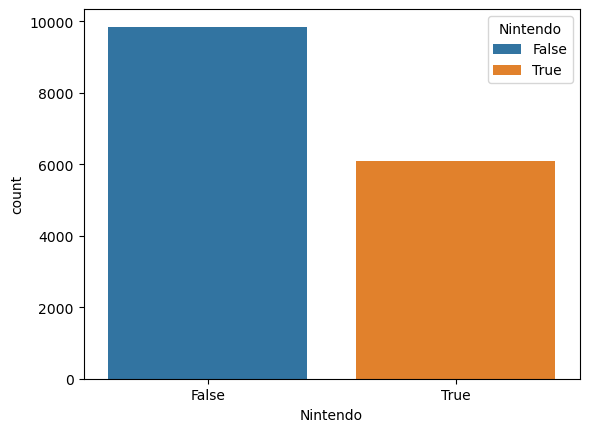

In [196]:
sns.countplot(classification, x="Nintendo", hue="Nintendo")
plt.show()

In [205]:
aggregateNintendo = classification.groupby("Nintendo").agg({'Nintendo': 'count'})
aggregateNintendo

,Nintendo
Nintendo,
False,9850
True,6095


In [210]:
NoNintendo = 9850/15945
YesNintendo = 6095/15945

In [211]:
print(NoNintendo, YesNintendo)

0.6177485105048605 0.38225148949513954


In [212]:
#assign X and Y values 

In [214]:
X = classification.iloc[:, :-1].values 

In [218]:
X

array([[4.149e+01, 2.902e+01, 3.770e+00, 8.460e+00, 8.274e+01],
       [2.908e+01, 3.580e+00, 6.810e+00, 7.700e-01, 4.024e+01],
       [1.585e+01, 1.288e+01, 3.790e+00, 3.310e+00, 3.582e+01],
       ...,
       [0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 1.000e-02],
       [0.000e+00, 1.000e-02, 0.000e+00, 0.000e+00, 1.000e-02],
       [1.000e-02, 0.000e+00, 0.000e+00, 0.000e+00, 1.000e-02]])

In [216]:
Y = classification.iloc[:, -1].values

In [217]:
Y

array([ True,  True,  True, ..., False,  True,  True])

In [219]:
#perform train and test split 
#set test data to 30% 
#set train data to 70% 

In [220]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.30, random_state=42)

In [221]:
X_train

array([[0.14, 0.01, 0.  , 0.01, 0.16],
       [0.  , 0.  , 0.07, 0.  , 0.07],
       [0.  , 0.  , 0.29, 0.  , 0.29],
       ...,
       [1.69, 0.2 , 0.  , 0.06, 1.95],
       [0.  , 0.  , 0.01, 0.  , 0.01],
       [0.04, 0.03, 0.12, 0.01, 0.21]])

In [222]:
X_test

array([[0.15, 0.1 , 0.  , 0.02, 0.27],
       [0.08, 0.  , 0.  , 0.01, 0.09],
       [0.09, 0.84, 0.11, 0.15, 1.19],
       ...,
       [0.03, 0.01, 0.  , 0.  , 0.04],
       [0.02, 0.05, 0.  , 0.01, 0.08],
       [0.23, 0.01, 0.  , 0.02, 0.25]])

In [223]:
Y_train

array([ True, False, False, ..., False, False, False])

In [224]:
Y_test

array([False,  True,  True, ...,  True, False,  True])

In [225]:
#perform feature scaling 

In [226]:
from sklearn.preprocessing import StandardScaler 
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [227]:
X_train

array([[-0.16238556, -0.29683489, -0.24838373, -0.24866796, -0.26178642],
       [-0.34151167, -0.31864914, -0.03341939, -0.31518085, -0.32354514],
       [-0.34151167, -0.31864914,  0.64218281, -0.31518085, -0.17257938],
       ...,
       [ 1.82079642,  0.11763591, -0.24838373,  0.08389646,  0.96652591],
       [-0.34151167, -0.31864914, -0.21767454, -0.31518085, -0.36471762],
       [-0.29033278, -0.25320638,  0.12012656, -0.24866796, -0.22747602]])

In [228]:
X_test

array([[-0.14959084, -0.10050661, -0.24838373, -0.18215508, -0.18630354],
       [-0.23915389, -0.31864914, -0.24838373, -0.24866796, -0.30982098],
       [-0.22635917,  1.51374808,  0.08941737,  0.68251243,  0.44500783],
       ...,
       [-0.30312751, -0.29683489, -0.24838373, -0.31518085, -0.34413138],
       [-0.31592223, -0.20957788, -0.24838373, -0.24866796, -0.31668306],
       [-0.04723306, -0.29683489, -0.24838373, -0.18215508, -0.2000277 ]])

In [229]:
#build logistic classificatin model and return y predicted values

In [230]:
from sklearn.linear_model import LogisticRegression 
classifier = LogisticRegression()
classifier.fit(X_train, Y_train)

LogisticRegression()

In [231]:
y_pred = classifier.predict(X_test)

In [232]:
y_pred

array([False, False, False, ..., False, False, False])

In [233]:
#return confusion matrix and accuracy score of the values

In [235]:
from sklearn.metrics import confusion_matrix, accuracy_score
cm = confusion_matrix(Y_test, y_pred)
print(cm)
accuracy_score(Y_test, y_pred)

[[2852   97]
 [1693  142]]


0.6258361204013378

In [236]:
#the models returns with 62.6% accuracy not terribly effective at predicting whether a game is a nintendo game 
#can i optimize it further and increase the accuracy? 

**Logistic Classification Tuning (Hyper Parameter Tuning)**
- use hyperparameter tuning with grid search technique
- create a parameter grid for hyperparameter tuning
- get possible combination of hyperparameters
- apply best parametersto logistic classification model
- validate the accuracy of the model

The accuracy of the model slightly increased from 62.6% to 62.7% 

In [240]:
parameter_grid = [
    {'penalty': ['l1', 'l2', 'elasticnet', 'none'],
     'C': np.logspace(-4, 4, 20),
     'solver': ['lbfgs', 'liblinear', 'sag', 'saga'],
     'max_iter': [100, 1000, 2500, 5000]
    }
]

In [242]:
from sklearn.model_selection import GridSearchCV

In [243]:
clf = GridSearchCV(classifier, param_grid = parameter_grid, cv = 3, verbose=True, n_jobs=-1)
clf

GridSearchCV(cv=3, estimator=LogisticRegression(), n_jobs=-1,
             param_grid=[{'C': array([1.00000000e-04, 2.63665090e-04, 6.95192796e-04, 1.83298071e-03,
       4.83293024e-03, 1.27427499e-02, 3.35981829e-02, 8.85866790e-02,
       2.33572147e-01, 6.15848211e-01, 1.62377674e+00, 4.28133240e+00,
       1.12883789e+01, 2.97635144e+01, 7.84759970e+01, 2.06913808e+02,
       5.45559478e+02, 1.43844989e+03, 3.79269019e+03, 1.00000000e+04]),
                          'max_iter': [100, 1000, 2500, 5000],
                          'penalty': ['l1', 'l2', 'elasticnet', 'none'],
                          'solver': ['lbfgs', 'liblinear', 'sag', 'saga']}],
             verbose=True)

In [244]:
best_clf = clf.fit(X, Y)
best_clf.best_estimator_

Fitting 3 folds for each of 1280 candidates, totalling 3840 fits


C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:540: FitFailedWarning: 
2400 fits failed out of a total of 3840.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
240 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 888, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\base.py", line 1473, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\alexh\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py", line 1194, in fit
    solve

LogisticRegression(C=78.47599703514607, solver='sag')

In [245]:
print(f'Accuracy - : {best_clf.score(X, Y):.3f}')

Accuracy - : 0.627


**Try to run the model again but with specifying the class balanced argument**

- balancing the y value did not work, the accuracy score decreased from 62.7% to 60.1%

In [246]:
X = classification.iloc[:, :-1].values 

In [247]:
Y = classification.iloc[:, -1].values

In [249]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.30, random_state=42)

In [252]:
from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression(class_weight='balanced')
classifier.fit(X, Y)

LogisticRegression(class_weight='balanced')

In [253]:
y_pred = classifier.predict(X_test)

In [254]:
y_pred

array([False, False, False, ..., False, False, False])

In [258]:
from sklearn.metrics import confusion_matrix, balanced_accuracy_score
cm = confusion_matrix(Y_test, y_pred)
print(cm)
balanced_accuracy_score(Y_test, y_pred)

[[2069  880]
 [ 914  921]]


0.6017505587725207

**Instead of Standard Scaler Try Min Max Scaler to standardize the features**
- do not balance the data, no need to do this
- The accuracy score decreased from 62.58% standard scaler to 62.52% min max scaler

In [270]:
X = classification.iloc[:, :-1].values 

In [271]:
Y = classification.iloc[:, -1].values

In [272]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.30, random_state=42)

In [273]:
from sklearn.preprocessing import MinMaxScaler 
sc = MinMaxScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [274]:
from sklearn.linear_model import LogisticRegression 
classifier = LogisticRegression()
classifier.fit(X_train, Y_train)

LogisticRegression()

In [275]:
y_pred = classifier.predict(X_test)

In [276]:
y_pred

array([False, False, False, ..., False, False, False])

In [277]:
from sklearn.metrics import confusion_matrix, accuracy_score
cm = confusion_matrix(Y_test, y_pred)
print(cm)
accuracy_score(Y_test, y_pred)

[[2928   21]
 [1772   63]]


0.6252090301003345

**Try Different Classification Models**
- random forest
- decision tree
- support vector machine

**Random Forest Classification Model**
- The accuracy percentage of the model decreases from 62.58 (Logistic Classification) to 62.52 Random Forest

In [286]:
X = classification.iloc[:, :-1].values

In [287]:
Y = classification.iloc[:, -1].values

In [288]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.30, random_state=42)

In [289]:
from sklearn.preprocessing import StandardScaler 
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [290]:
from sklearn.ensemble import RandomForestClassifier
classifier = RandomForestClassifier(n_estimators=10, criterion='entropy', random_state=0)
classifier.fit(X_train, Y_train)

RandomForestClassifier(criterion='entropy', n_estimators=10, random_state=0)

In [291]:
from sklearn.metrics import confusion_matrix, accuracy_score 
cm = confusion_matrix(Y_test, y_pred)
print(cm)
accuracy_score(Y_test, y_pred)

[[2928   21]
 [1772   63]]


0.6252090301003345

**Decision Tree Model**
- The accuracy percentage of the model decreases from 62.58 (Logistic Classification) to 62.52 Decision Tree

In [303]:
X = classification.iloc[:, :-1].values
Y = classification.iloc[:, -1].values

In [304]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.30, random_state=42)

In [305]:
from sklearn.preprocessing import StandardScaler 
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [306]:
from sklearn.tree import DecisionTreeClassifier
classifier = DecisionTreeClassifier(criterion='entropy', random_state=0)
classifier.fit(X_train, Y_train)

DecisionTreeClassifier(criterion='entropy', random_state=0)

In [307]:
from sklearn.metrics import confusion_matrix, accuracy_score 
cm = confusion_matrix(Y_test, y_pred)
print(cm)
accuracy_score(Y_test, y_pred)

[[2928   21]
 [1772   63]]


0.6252090301003345

**Support Vector Machine Model**
- The accuracy percentage of the model decreases from 62.58 (Logistic Classification) to 62.52 Decision Tree

In [308]:
X = classification.iloc[:, :-1].values
Y = classification.iloc[:, -1].values

In [309]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.30, random_state=42)

In [310]:
from sklearn.preprocessing import StandardScaler 
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [312]:
from sklearn.svm import SVC
classifier = SVC(kernel = 'linear', random_state = 0)
classifier.fit(X_train, Y_train)

SVC(kernel='linear', random_state=0)

In [314]:
from sklearn.metrics import confusion_matrix, accuracy_score
cm = confusion_matrix(Y_test, y_pred)
print(cm)
accuracy_score(Y_test, y_pred)

[[2928   21]
 [1772   63]]


0.6252090301003345

**Conclusions from Classification Model**
- The accuracy of the Logistic Classification model is 62.58%, the sales data is not a strong indicator of whether the video games is a nintendo game
- The only feature engineering trick that increased the accuracy of the model is the grid search method, the accuracy slightly increases from 62.58% to 62.7%
- The decision tree, random forest and SVM classification models all performed worse than the logistic classification model, the accuracy for all three of these models is 62.52%